# Homework 3

46-921, Financial Data Science I

Submitted by Kun Yang

In [1]:
import numpy as np
import pandas as pd

In [2]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

In [3]:
data = pd.read_csv("http://www.stat.cmu.edu/~cschafer/MSCF/bonddata.txt")

In [4]:
data.head()

,id,bond_id,trade_price,weight,current_coupon,time_to_maturity,is_callable,reporting_delay,trade_size,trade_type,...,received_time_diff_last9,trade_price_last9,trade_size_last9,trade_type_last9,curve_based_price_last9,received_time_diff_last10,trade_price_last10,trade_size_last10,trade_type_last10,curve_based_price_last10
0,10,1,126.268,7.616851,5.950,25.940349,0,12.540,150000.0,3,...,2862729,128.596,120000.0,2,127.561201,3621492,129.089,200000.0,2,129.435587
1,38,2,101.009,0.018373,3.550,0.326392,0,9.327,450000.0,3,...,532644,101.086,500000.0,2,101.103180,538510,101.070,25000.0,2,101.102243
2,336,3,108.144,3.537380,4.200,2.340601,0,0.102,160000.0,4,...,96293,107.917,400000.0,2,107.874965,96293,107.917,400000.0,4,107.874965
3,781,4,116.953,0.402523,4.875,7.367653,0,52.093,10000.0,4,...,92559,115.924,10000.0,2,116.160420,97177,116.458,2000.0,3,116.342802
4,1172,14,133.210,0.210685,10.750,4.159301,0,13.722,25000.0,4,...,6400208,127.500,25000.0,2,131.066998,6400208,127.500,25000.0,4,131.066998


In [5]:
data.shape

(1620, 61)

In [6]:
data = data.drop(['id', 'bond_id'], axis=1)

In [7]:
cols = ['is_callable', 'trade_type'] + [f'trade_type_last{i}' for i in range(1, 11)]
data[cols] = data[cols].apply(lambda col: col.astype('category').cat.as_unordered())

<Axes: >

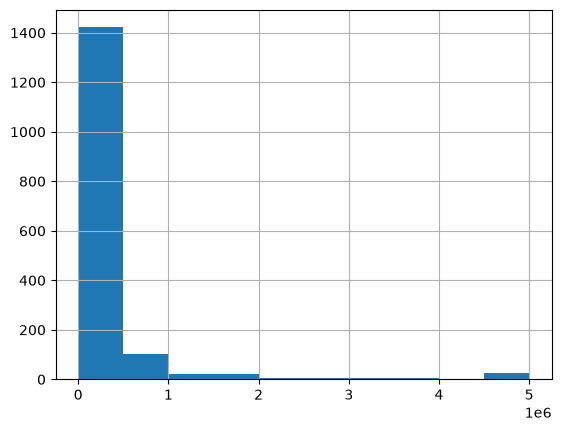

In [8]:
data['trade_size_last1'].hist()

In [9]:
log_cols = ['time_to_maturity', 'trade_size'] + [f'trade_size_last{i}' for i in range(1, 11)]
for col in log_cols:
    data[f'{col}_lt'] = np.log(data[col])

sqrt_cols = [f'received_time_diff_last{i}' for i in range(1, 11)]
for col in sqrt_cols:
    data[f'{col}_st'] = np.sqrt(data[col])

In [10]:
cols_to_drop = (
    [f'received_time_diff_last{i}' for i in range(1, 11)] +
    [f'trade_size_last{i}' for i in range(1, 11)] +
    ['time_to_maturity', 'trade_size']
)
datatransformed = data.drop(cols_to_drop, axis=1)

In [11]:
datatransformed.head()

,trade_price,weight,current_coupon,is_callable,reporting_delay,trade_type,curve_based_price,trade_price_last1,trade_type_last1,curve_based_price_last1,...,received_time_diff_last1_st,received_time_diff_last2_st,received_time_diff_last3_st,received_time_diff_last4_st,received_time_diff_last5_st,received_time_diff_last6_st,received_time_diff_last7_st,received_time_diff_last8_st,received_time_diff_last9_st,received_time_diff_last10_st
0,126.268,7.616851,5.950,0,12.540,3,126.017363,125.101,3,124.717608,...,586.299412,587.409568,827.276254,1138.199455,1143.881113,1467.292745,1468.805637,1551.676835,1691.960106,1903.021808
1,101.009,0.018373,3.550,0,9.327,3,101.068546,101.009,2,101.068546,...,1.000000,60.778286,89.543286,95.749674,135.440024,590.292300,669.789519,723.537145,729.824636,733.832406
2,108.144,3.537380,4.200,0,0.102,4,107.927659,107.990,2,107.922875,...,272.284777,273.237992,289.815459,289.891359,291.082463,291.082463,292.518375,303.326557,310.311134,310.311134
3,116.953,0.402523,4.875,0,52.093,4,116.552464,115.842,2,116.542486,...,30.967725,32.969683,114.860785,294.277080,294.348433,302.160553,302.162208,302.162208,304.235106,311.732257
4,133.210,0.210685,10.750,0,13.722,4,130.202417,133.612,4,130.211787,...,16.186414,829.783104,1692.365504,1993.787852,1993.787852,2351.207137,2354.411816,2355.126536,2529.863237,2529.863237


In [12]:
designmatrix = pd.get_dummies(datatransformed,drop_first=True)

In [13]:
import statsmodels.api as sm

designmatrix_withones = sm.add_constant(designmatrix)

## Exercises

Now, do each of the following:

1. Fit the model using including all of the predictors (i.e., using the entire design matrix you just constructed), via `sm.OLS`. Remember that `trade_price` is the response. Show the `summary` output.

2. Construct the plot of residuals versus fitted values for the model fit in Question 1. Comment on the quality of the fit.

3. Construct the normal probability plot of the residuals. What does this plot tell us?

4. Implement a stepwise variable selection procedure using AIC to find a simpler model. Report on the resulting model.

5. Repeat the above, but use leave-one-out cross-validation instead of AIC. How does the resulting model change? 

# Exercises 1: Full model

In [14]:
y = designmatrix_withones['trade_price']
X = designmatrix_withones.drop(columns=['trade_price'])

In [15]:
model_full = sm.OLS(y, X).fit()
model_full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            trade_price   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                     1128.
Date:                Sat, 19 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:35:00   Log-Likelihood:                -3065.8
No. Observations:                1620   AIC:                             6272.
Df Residuals:                    1550   BIC:                             6649.
Df Model:                          69                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.6567      0.664      0.988      0.323      -0.647       1.960
weight                          -8.3318     13.550     -0.615      0.539     -34.911      18.247
current_coupon                   0.0252      0.030      0.838      0.402      -0.034       0.084
reporting_delay              -1.618e-06   1.24e-06     -1.304      0.192   -4.05e-06    8.16e-07
curve_based_price                0.3916      0.040      9.693      0.000       0.312       0.471
trade_price_last1                0.4094      0.036     11.266      0.000       0.338       0.481
curve_based_price_last1         -0.0295      0.068     -0.435      0.663      -0.162       0.103
trade_price_last2                0.0330      0.040      0.831      0.406      -0.045       0.111
curve_based_price_last2         -0.0682      0.071     -0.964      0.335      -0.207       0.071
trade_price_last3                0.0485      0.037      1.304      0.192      -0.024       0.121
curve_based_price_last3         -0.1338      0.072     -1.857      0.063      -0.275       0.008
trade_price_last4                0.0877      0.035      2.502      0.012       0.019       0.156
curve_based_price_last4          0.2051      0.076      2.709      0.007       0.057       0.354
trade_price_last5                0.0432      0.037      1.180      0.238      -0.029       0.115
curve_based_price_last5         -0.2475      0.074     -3.360      0.001      -0.392      -0.103
trade_price_last6               -0.0383      0.036     -1.056      0.291      -0.109       0.033
curve_based_price_last6          0.1129      0.072      1.559      0.119      -0.029       0.255
trade_price_last7                0.1130      0.036      3.126      0.002       0.042       0.184
curve_based_price_last7         -0.0657      0.070     -0.938      0.349      -0.203       0.072
trade_price_last8                0.0140      0.033      0.421      0.674      -0.051       0.079
curve_based_price_last8         -0.0381      0.069     -0.550      0.582      -0.174       0.098
trade_price_last9                0.0638      0.034      1.865      0.062      -0.003       0.131
curve_based_price_last9         -0.0007      0.065     -0.010      0.992      -0.128       0.127
trade_price_last10               0.0332      0.030      1.099      0.272      -0.026       0.092
curve_based_price_last10         0.0546      0.053      1.020      0.308      -0.050       0.160
time_to_maturity_lt             -0.0019      0.045     -0.043      0.966      -0.089       0.085
trade_size_lt                    0.1361      0.026      5.205      0.000       0.085       0.187
trade_size_last1_lt             -0.0807      0.031     -2.600      0.009      -0.142      -0.020
trade_size_last2_lt              0.0253      0.034      0.743      0.458    

# Exercise 2: plot residual vs fitted value

In [16]:
import matplotlib.pyplot as plt

fit = model_full.fittedvalues
res = model_full.resid

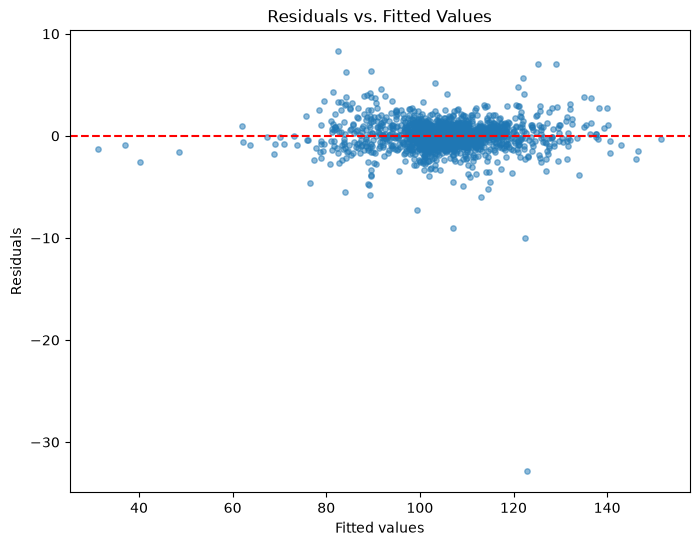

In [17]:
plt.figure(figsize=(8, 6))
plt.scatter(fit, res, alpha=0.5, s=15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values')
plt.show()

Comments: The model fits well with R-Square 0.98, and the residuals are around fitted value with no obvious patterns. However there are clearly extrem values with abs(residual) around 10, with one point with -30 and beyond redidual. those illiquid prices will distort the prediction model and it is better to remove them. Also, the spread of residuals are not constant from above pictures.

# Exercise 3: Q-Q plot

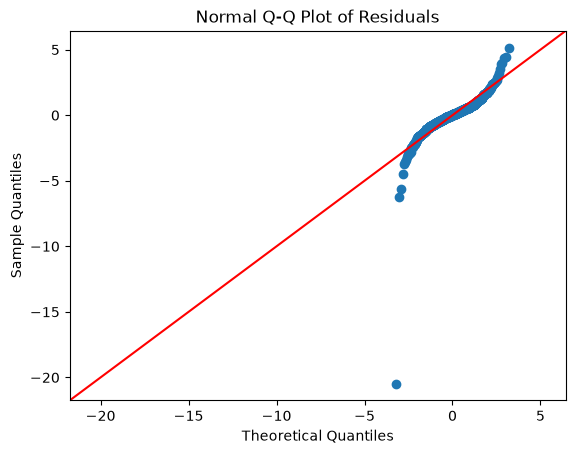

In [18]:
import scipy.stats as stats

fig = sm.qqplot(res, line='45', fit=True)
plt.title('Normal Q-Q Plot of Residuals')
plt.show()

Comments: from Q-Q plot above, the residual deviate sharply from 45 degree line as Normal residual, so it shows heavy tails in both sides. The residual has skew -5.4 and kurtosis 111. We can see the impact of those large rediduals from previous plot here, with the one extreme point from that -33 residual. J-B test reject the normality of residual with very tiny p-value

# Exercise 4: implement a stewise variable selection procedure using AIC

In [19]:
pred_col = designmatrix.drop(columns=['trade_price']).columns.tolist()
pred = designmatrix[pred_col]
pred.shape

(1620, 69)

we have 69 candidates to start with...

In [20]:
def fit_ols(cols):
    if(cols)==[]:
        Xc = sm.add_constant(pd.DataFrame(index=pred.index))
    else:
        Xc = sm.add_constant(pred[cols])
    return sm.OLS(y, Xc).fit()

In [21]:
def aic(cols):
    return fit_ols(cols).aic

In [22]:
my_aic=aic(pred_col)
print(f"AIC of the full model: {my_aic}")

AIC of the full model: 6271.683402188058


In [23]:
def stepwise_selection_aic(verbose=False):
    included = []
    current_aic = aic(included)
    while True:
        changed = False

        # --- forward step: try adding each excluded predictor ---
        excluded = [c for c in pred if c not in included]
        best_aic, best_feature = current_aic, None
        for col in excluded:
            candidate_aic = aic(included + [col])
            if candidate_aic < best_aic:
                best_aic, best_feature = candidate_aic, col
        if best_feature is not None:
            included.append(best_feature)
            current_aic = best_aic
            changed = True
            if verbose:
                print(f'+ {best_feature:35s} {current_aic:.3f}')

        # --- backward step: try removing each included predictor ---
        if included:
            best_aic, worst_feature = current_aic, None
            for col in included:
                trial = [c for c in included if c != col]
                candidate_aic = aic(trial)
                if candidate_aic < best_aic:
                    best_aic, worst_feature = candidate_aic, col
            if worst_feature is not None:
                included.remove(worst_feature)
                current_aic = best_aic
                changed = True
                if verbose:
                    print(f'- {worst_feature:35s} {current_aic:.3f}')

        if not changed:
            break
    return included, current_aic

aic_selected, aic_score = stepwise_selection_aic(verbose=True)

+ trade_price_last1                   6921.837
+ curve_based_price                   6624.830
+ trade_type_3                        6500.884
+ trade_price_last7                   6395.546
+ trade_type_4                        6335.233
+ trade_price_last10                  6306.663
+ trade_price_last4                   6290.119
+ curve_based_price_last5             6265.633
+ trade_size_lt                       6252.017
+ trade_type_last1_3                  6238.012
+ trade_type_last4_3                  6229.194
+ trade_size_last1_lt                 6222.550
+ trade_type_last1_4                  6219.168
+ trade_type_last4_4                  6217.158
+ trade_type_last5_3                  6215.171
+ trade_price_last9                   6213.630
+ curve_based_price_last2             6211.779
+ curve_based_price_last4             6210.183
+ trade_size_last4_lt                 6208.992
+ is_callable_1                       6208.185
+ curve_based_price_last3             6207.487
+ trade_price

In [24]:
print(len(aic_selected))

23


So final AIC is 6205.575, and 23 candidates were selected by stepwise selection using AIC

In [25]:
model_aic = fit_ols(aic_selected)
model_aic.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            trade_price   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                     3429.
Date:                Sat, 19 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:35:14   Log-Likelihood:                -3078.8
No. Observations:                1620   AIC:                             6206.
Df Residuals:                    1596   BIC:                             6335.
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.6990      0.552      1.266      0.206      -0.384       1.782
trade_price_last1                0.4269      0.027     15.858      0.000       0.374       0.480
curve_based_price                0.3586      0.030     11.757      0.000       0.299       0.418
trade_type_3                     1.6053      0.109     14.680      0.000       1.391       1.820
trade_price_last7                0.1098      0.023      4.736      0.000       0.064       0.155
trade_type_4                     0.8925      0.100      8.882      0.000       0.695       1.090
trade_price_last10               0.0535      0.026      2.085      0.037       0.003       0.104
trade_price_last4                0.1083      0.030      3.584      0.000       0.049       0.168
curve_based_price_last5         -0.1952      0.050     -3.911      0.000      -0.293      -0.097
trade_size_lt                    0.1367      0.025      5.418      0.000       0.087       0.186
trade_type_last1_3              -0.4461      0.114     -3.909      0.000      -0.670      -0.222
trade_type_last4_3              -0.4218      0.121     -3.474      0.001      -0.660      -0.184
trade_size_last1_lt             -0.0737      0.025     -2.901      0.004      -0.124      -0.024
trade_type_last1_4              -0.2397      0.106     -2.264      0.024      -0.447      -0.032
trade_type_last4_4              -0.2117      0.105     -2.023      0.043      -0.417      -0.006
trade_type_last5_3              -0.1605      0.088     -1.829      0.068      -0.333       0.012
trade_price_last9                0.0563      0.027      2.068      0.039       0.003       0.110
curve_based_price_last4          0.2053      0.074      2.780      0.005       0.060       0.350
trade_size_last4_lt             -0.0407      0.024     -1.704      0.089      -0.088       0.006
is_callable_1                    0.2132      0.119      1.788      0.074      -0.021       0.447
curve_based_price_last3         -0.1858      0.061     -3.033      0.002      -0.306      -0.066
trade_price_last3                0.0511      0.030      1.688      0.092      -0.008       0.110
received_time_diff_last10_st    -0.0004      0.000     -2.046      0.041      -0.001   -1.73e-05
received_time_diff_last8_st      0.0004      0.000      1.699      0.089   -5.72e-05       0.001
==============================================================================
Omnibus:                     1909.695   Durbin-Watson:                   1.989
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           866054.451
Skew:                          -5.436   Prob(JB):                         0.00
Kurtosis:                     115.749   Cond. No.                     2.57e+04
=====================================================================

So using stepwise, the candidates dropped from 69 to 23 with same R-Square as 0.98.

# Exercise 5: using leave-one-out cross-validation as criteria for stepwise selection

In [26]:
m=fit_ols(pred_col)
h = m.get_influence().hat_matrix_diag
print(h)

[0.05501728 0.04405496 0.02859193 ... 0.0444608  0.06859595 0.08885119]


In [27]:
np.sum((m.resid / (1 - h)) ** 2)/len(m.resid) 

np.float64(2.90721202782844)

In [28]:
def loocv(cols):
    m = fit_ols(cols)
    h = m.get_influence().hat_matrix_diag
    press = np.sum((m.resid / (1 - h)) ** 2)
    return press / len(y)

In [29]:
my_loocv=loocv(pred_col)
print(f"LOOCV of the full model: {my_loocv}")

LOOCV of the full model: 2.90721202782844


In [30]:
def stepwise_selection_loocv(verbose=False):
    included = []
    current_loocv = loocv(included)
    while True:
        changed = False

        # --- forward step: try adding each excluded predictor ---
        excluded = [c for c in pred if c not in included]
        best_loocv, best_feature = current_loocv, None
        for col in excluded:
            candidate_loocv = loocv(included + [col])
            if candidate_loocv < best_loocv:
                best_loocv, best_feature = candidate_loocv, col
        if best_feature is not None:
            included.append(best_feature)
            current_loocv = best_loocv
            changed = True
            if verbose:
                print(f'+ {best_feature:35s} {current_loocv:.3f}')

        # --- backward step: try removing each included predictor ---
        if included:
            best_loocv, worst_feature = current_loocv, None
            for col in included:
                trial = [c for c in included if c != col]
                candidate_loocv = loocv(trial)
                if candidate_loocv < best_loocv:
                    best_loocv, worst_feature = candidate_loocv, col
            if worst_feature is not None:
                included.remove(worst_feature)
                current_loocv = best_loocv
                changed = True
                if verbose:
                    print(f'- {worst_feature:35s} {current_loocv:.3f}')

        if not changed:
            break
    return included, current_loocv

loocv_selected, loocv_score = stepwise_selection_loocv(verbose=True)

+ trade_price_last1                   4.206
+ curve_based_price                   3.507
+ trade_type_3                        3.250
+ trade_price_last7                   3.049
+ trade_type_4                        2.936
+ trade_price_last10                  2.889
+ trade_type_last1_3                  2.862
+ curve_based_price_last5             2.835
+ trade_price_last4                   2.803
+ trade_size_lt                       2.780
+ trade_type_last4_3                  2.764
+ trade_size_last1_lt                 2.752
+ trade_type_last1_4                  2.746
+ is_callable_1                       2.742
+ trade_type_last4_4                  2.739
+ trade_size_last4_lt                 2.736
+ trade_type_last7_3                  2.735
+ trade_type_last5_3                  2.734
+ reporting_delay                     2.734
+ trade_price_last9                   2.734
+ received_time_diff_last10_st        2.733
+ received_time_diff_last7_st         2.732
- reporting_delay               

In [31]:
print(len(loocv_selected))

21


Note: using loocv stepwise selection, the optimal candidates are 21, so slightly less than using AIC.

In [32]:
model_loocv = fit_ols(loocv_selected)
model_loocv.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            trade_price   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                     3738.
Date:                Sat, 19 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:35:26   Log-Likelihood:                -3083.5
No. Observations:                1620   AIC:                             6211.
Df Residuals:                    1598   BIC:                             6330.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.7213      0.553      1.304      0.192      -0.363       1.806
trade_price_last1                0.4276      0.026     16.768      0.000       0.378       0.478
curve_based_price                0.3470      0.028     12.359      0.000       0.292       0.402
trade_type_3                     1.5898      0.109     14.525      0.000       1.375       1.804
trade_price_last7                0.1233      0.025      4.943      0.000       0.074       0.172
trade_type_4                     0.8966      0.101      8.900      0.000       0.699       1.094
trade_price_last10               0.0593      0.026      2.320      0.020       0.009       0.109
trade_type_last1_3              -0.4452      0.114     -3.913      0.000      -0.668      -0.222
curve_based_price_last5         -0.1563      0.029     -5.416      0.000      -0.213      -0.100
trade_price_last4                0.1406      0.025      5.713      0.000       0.092       0.189
trade_size_lt                    0.1376      0.025      5.438      0.000       0.088       0.187
trade_type_last4_3              -0.4534      0.121     -3.756      0.000      -0.690      -0.217
trade_size_last1_lt             -0.0716      0.025     -2.810      0.005      -0.122      -0.022
trade_type_last1_4              -0.2307      0.106     -2.179      0.029      -0.438      -0.023
is_callable_1                    0.2175      0.120      1.820      0.069      -0.017       0.452
trade_type_last4_4              -0.2221      0.105     -2.118      0.034      -0.428      -0.016
trade_size_last4_lt             -0.0432      0.024     -1.802      0.072      -0.090       0.004
trade_type_last7_3              -0.1289      0.094     -1.378      0.168      -0.313       0.055
trade_type_last5_3              -0.1635      0.088     -1.858      0.063      -0.336       0.009
trade_price_last9                0.0475      0.027      1.751      0.080      -0.006       0.101
received_time_diff_last10_st    -0.0003      0.000     -1.936      0.053      -0.001    4.26e-06
received_time_diff_last7_st      0.0003      0.000      1.575      0.115   -7.19e-05       0.001
==============================================================================
Omnibus:                     1928.610   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           895357.127
Skew:                          -5.533   Prob(JB):                         0.00
Kurtosis:                     117.639   Cond. No.                     2.50e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.5e+04. This might indicate that there are
stron

with 21 candidated seleted by stepwise selection using loocv, the R-square remains as 0.98

In [33]:
added = sorted(set(loocv_selected) - set(aic_selected))
dropped = sorted(set(aic_selected) - set(loocv_selected))
print('In LOOCV model but not in AIC model:', added)
print('In AIC model but not in LOOCV model:', dropped)

In LOOCV model but not in AIC model: ['received_time_diff_last7_st', 'trade_type_last7_3']
In AIC model but not in LOOCV model: ['curve_based_price_last3', 'curve_based_price_last4', 'received_time_diff_last8_st', 'trade_price_last3']


We can see that the candidates list changes from 23 to 21, and there are a few difference as above. but the R-Square remains as 0.98, so basically using either list as predictors will be a good multi regression model here.

In [5]:
import sys
print(sys.executable)

c:\Users\Administrator\financial_data_analysis_1\financial_data_analysis_1\.venv\Scripts\python.exe
